# 1. Setup and imports

This notebook predicts aqueous solubility from molecular structure. We first load the libraries and define the project paths used throughout the workflow.

In [1]:
from pathlib import Path
import sys

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
requirements_path = project_root / "requirements.txt"

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

%pip install -r "{requirements_path}"
%pip install deepchem

import pandas as pd
import numpy as np
import json

from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold

from src.evaluation import get_scaffold
from src.features import compute_descriptors
from src.features import compute_morgan
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.ensemble import RandomForestRegressor

from src.features import compute_descriptors, compute_morgan
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from sklearn.model_selection import GroupShuffleSplit




Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


# 2. Load the cleaned solubility dataset

The cleaned dataset contains canonical SMILES and the continuous solubility target. Loading the processed file keeps this modeling notebook separate from the exploratory cleaning workflow.

In [2]:
processed_dir = project_root / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

df_reg = pd.read_csv(processed_dir / "solubility_clean.csv")
display(df_reg.head())

,Drug_ID,SMILES,Solubility,Canonical_smiles
0,"N,N,N-trimethyloctadecan-1-aminium bromide",CCCCCCCCCCCCCCCCCC[N+](C)(C)C.[Br-],-3.616127,CCCCCCCCCCCCCCCCCC[N+](C)(C)C.[Br-]
1,Benzo[cd]indol-2(1H)-one,O=C1Nc2cccc3cccc1c23,-3.254767,O=C1Nc2cccc3cccc1c23
2,4-chlorobenzaldehyde,O=Cc1ccc(Cl)cc1,-2.177078,O=Cc1ccc(Cl)cc1
3,"zinc bis[2-hydroxy-3,5-bis(1-phenylethyl)benzo...",CC(c1ccccc1)c1cc(C(=O)[O-])c(O)c(C(C)c2ccccc2)...,-3.924409,CC(c1ccccc1)c1cc(C(=O)[O-])c(O)c(C(C)c2ccccc2)...
4,4-({4-[bis(oxiran-2-ylmethyl)amino]phenyl}meth...,c1cc(N(CC2CO2)CC2CO2)ccc1Cc1ccc(N(CC2CO2)CC2CO...,-4.662065,c1cc(N(CC2CO2)CC2CO2)ccc1Cc1ccc(N(CC2CO2)CC2CO...


# 3. Inspect Bemis–Murcko scaffolds

Molecules sharing the same scaffold can have similar chemical behavior. We assign a Bemis–Murcko scaffold to each molecule and remove structures that cannot be interpreted before splitting the data.

In [3]:

smiles_col = "Canonical_smiles"
df_reg["scaffold"] = df_reg[smiles_col].apply(get_scaffold)

invalid_count = df_reg["scaffold"].isna().sum()
print("Invalid SMILES:", invalid_count)

# Remove molecules with invalid structures.
df_reg = df_reg.dropna(subset=["scaffold"]).copy()

print("Valid molecules:", len(df_reg))
print("Unique scaffolds:", df_reg["scaffold"].nunique())

# Inspect the largest groups.
display(df_reg["scaffold"].value_counts().head(10))


[21:57:49] WARNING: not removing hydrogen atom without neighbors
[21:57:49] WARNING: not removing hydrogen atom without neighbors
[21:57:49] WARNING: not removing hydrogen atom without neighbors
[21:57:49] WARNING: not removing hydrogen atom without neighbors
[21:57:49] WARNING: not removing hydrogen atom without neighbors
[21:57:49] WARNING: not removing hydrogen atom without neighbors
[21:57:49] WARNING: not removing hydrogen atom without neighbors
[21:57:49] WARNING: not removing hydrogen atom without neighbors
[21:57:49] WARNING: not removing hydrogen atom without neighbors
[21:57:49] WARNING: not removing hydrogen atom without neighbors
[21:57:49] WARNING: not removing hydrogen atom without neighbors
[21:57:49] WARNING: not removing hydrogen atom without neighbors
[21:57:49] WARNING: not removing hydrogen atom without neighbors
[21:57:49] WARNING: not removing hydrogen atom without neighbors
[21:57:49] WARNING: not removing hydrogen atom without neighbors
[21:57:49] WARNING: not r

Invalid SMILES: 0
Valid molecules: 9982
Unique scaffolds: 4996


scaffold
c1ccccc1                 1753
c1ccc(-c2ccccc2)cc1       219
c1ccc2ccccc2c1            152
c1ccc(Oc2ccccc2)cc1       139
C1CCCCC1                  117
c1ccncc1                  102
c1ccc(Cc2ccccc2)cc1        73
c1ccc(N=Nc2ccccc2)cc1      61
O=c1cc[nH]c(=O)[nH]1       52
O=C1CC(=O)NC(=O)N1         49
Name: count, dtype: int64

# 4. Create a scaffold-disjoint train/test split

The held-out test set contains scaffolds that are absent from training. This gives a stricter estimate of performance on new chemical cores.

In [4]:
# Size of each scaffold group
scaffold_sizes = df_reg["scaffold"].value_counts()

print(scaffold_sizes.describe())
print("Largest scaffold group:", scaffold_sizes.max())

# Splitting our molecules by scafold 


splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(df_reg, groups=df_reg["scaffold"])
)
assert df_reg["scaffold"].notna().all(), "Invalid structures to inspect."

train_df = df_reg.iloc[train_idx].copy()
test_df = df_reg.iloc[test_idx].copy()

print("Training set:", len(train_df), "molecules")
print("Test set:", len(test_df), "molecules")
print("Test proportion:", round(len(test_df) / len(df_reg) * 100, 2), "%")


count    4996.000000
mean        1.997998
std        25.393243
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max      1753.000000
Name: count, dtype: float64
Largest scaffold group: 1753
Training set: 8354 molecules
Test set: 1628 molecules
Test proportion: 16.31 %


# 5. Save the split assignments

The split is saved so that every representation and model is evaluated on exactly the same molecules.

In [5]:
df_reg["split"] = "train"
df_reg.loc[test_df.index, "split"] = "test"

df_reg.to_csv(processed_dir / "saved_scaffold_split_solubility.csv", index=False)

print(df_reg["split"].value_counts())
print("Split assignments saved showing which columns will be used for training and which will be used for testing.")

split
train    8354
test     1628
Name: count, dtype: int64
Split assignments saved showing which columns will be used for training and which will be used for testing.


# 6. Check for scaffold leakage

We verify that no scaffold appears in both partitions. Sharing scaffolds would make the test score overly optimistic.

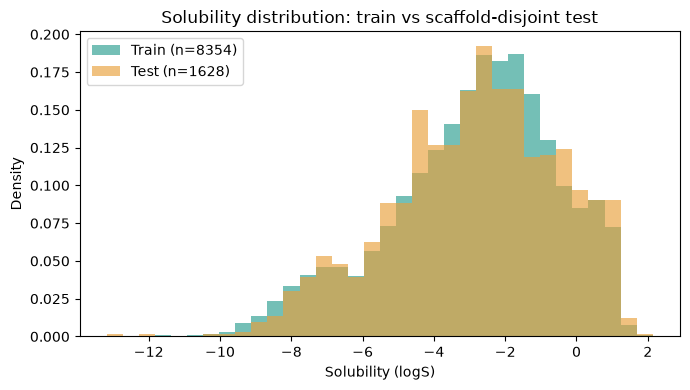

count    8354.000000
mean       -2.896363
std         2.369664
min       -12.950000
25%        -4.313364
50%        -2.600150
75%        -1.223119
max         2.137682
Name: Solubility, dtype: float64
count    1628.000000
mean       -2.856788
std         2.360840
min       -13.171900
25%        -4.362500
50%        -2.678983
75%        -1.085275
max         1.700916
Name: Solubility, dtype: float64


In [6]:
df = pd.read_csv(project_root / "data" / "processed" / "saved_scaffold_split_solubility.csv")
train_df = df[df["split"] == "train"]
test_df = df[df["split"] == "test"]


# Graphical Visualization of the distribution of solubility values in the training and test sets.
import matplotlib.pyplot as plt

figures_dir = project_root / "results" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

bins = np.linspace(df["Solubility"].min(), df["Solubility"].max(), 35)

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(train_df["Solubility"], bins=bins, density=True, alpha=0.65,
        color="#2A9D8F", label=f"Train (n={len(train_df)})")
ax.hist(test_df["Solubility"], bins=bins, density=True, alpha=0.65,
        color="#E9A03B", label=f"Test (n={len(test_df)})")
ax.set_xlabel("Solubility (logS)")
ax.set_ylabel("Density")
ax.set_title("Solubility distribution: train vs scaffold-disjoint test")
ax.legend()
fig.tight_layout()
fig.savefig(figures_dir / "fig_target_train_test.png", dpi=200)
plt.show()

assert set(train_df["scaffold"]).isdisjoint(set(test_df["scaffold"]))
print(train_df["Solubility"].describe())
print(test_df["Solubility"].describe())

# 7. Generate and inspect molecular representations

We calculate RDKit descriptors and 2,048-bit Morgan fingerprints after the scaffold split. The checks verify dimensions, missing values, valid ranges, and alignment with the target values.

In [7]:
# Compute descriptors for training and test molecules.
X_train_desc = compute_descriptors(train_df["Canonical_smiles"])
X_test_desc = compute_descriptors(test_df["Canonical_smiles"])

# Check dimensions and descriptor names.
assert len(X_train_desc) == len(train_df)
assert len(X_test_desc) == len(test_df)
assert X_train_desc.columns.equals(X_test_desc.columns)

# Inspect missing, infinite and excessively large values.
float32_max = np.finfo(np.float32).max

for name, X_desc, molecules in [
    ("Train", X_train_desc, train_df),
    ("Test", X_test_desc, test_df),
]:
    checks = pd.DataFrame({
        "missing": X_desc.isna().sum(),
        "infinite": np.isinf(X_desc).sum(),
        "too_large_float32": (
            np.isfinite(X_desc)
            & (X_desc.abs() > float32_max)
        ).sum(),
    })

    missing_mask = X_desc.isna().any(axis=1)

    print(f"\n{name}: {X_desc.shape[0]} molecules, "
          f"{X_desc.shape[1]} descriptors")
    print("Total missing values:", checks["missing"].sum())
    print("Descriptors with missing values:", (checks["missing"] > 0).sum())
    print("Molecules with missing values:", missing_mask.sum())
    print("Total infinite values:", checks["infinite"].sum())
    print("Total values exceeding float32 range:",
          checks["too_large_float32"].sum())

    # Show only descriptors affected by at least one issue.
    display(checks.loc[(checks > 0).any(axis=1)])

    # Show up to five molecules with missing descriptor values.
    if missing_mask.any():
        print("Examples of molecules with missing descriptor values:")
        display(
            molecules.loc[
                missing_mask,
                ["Drug_ID", "Canonical_smiles", "Solubility"],
            ].head()
        )

# Prepare targets and scaffold groups.
y_train = train_df["Solubility"].to_numpy()
y_test = test_df["Solubility"].to_numpy()
groups_train = train_df["scaffold"].to_numpy()

[21:57:54] WARNING: not removing hydrogen atom without neighbors
[21:57:54] WARNING: not removing hydrogen atom without neighbors
[21:57:54] WARNING: not removing hydrogen atom without neighbors
[21:57:55] WARNING: not removing hydrogen atom without neighbors
[21:57:55] WARNING: not removing hydrogen atom without neighbors
[21:57:55] WARNING: not removing hydrogen atom without neighbors
[21:57:55] WARNING: not removing hydrogen atom without neighbors
[21:57:55] WARNING: not removing hydrogen atom without neighbors
[21:57:55] WARNING: not removing hydrogen atom without neighbors
[21:57:58] WARNING: not removing hydrogen atom without neighbors
[21:57:58] WARNING: not removing hydrogen atom without neighbors
[21:57:58] WARNING: not removing hydrogen atom without neighbors
[21:57:59] WARNING: not removing hydrogen atom without neighbors
[21:57:59] WARNING: not removing hydrogen atom without neighbors
[21:57:59] WARNING: not removing hydrogen atom without neighbors
[21:57:59] WARNING: not r


Train: 8354 molecules, 210 descriptors
Total missing values: 6046
Descriptors with missing values: 12
Molecules with missing values: 724
Total infinite values: 0
Total values exceeding float32 range: 6


,missing,infinite,too_large_float32
MaxPartialCharge,64,0,0
MinPartialCharge,63,0,0
MaxAbsPartialCharge,64,0,0
MinAbsPartialCharge,63,0,0
BCUT2D_MWHI,724,0,0
BCUT2D_MWLOW,724,0,0
BCUT2D_CHGHI,724,0,0
BCUT2D_CHGLO,724,0,0
BCUT2D_LOGPHI,724,0,0
BCUT2D_LOGPLOW,724,0,0


Examples of molecules with missing descriptor values:


,Drug_ID,Canonical_smiles,Solubility
3,"zinc bis[2-hydroxy-3,5-bis(1-phenylethyl)benzo...",CC(c1ccccc1)c1cc(C(=O)[O-])c(O)c(C(C)c2ccccc2)...,-3.924409
22,aluminium(3+) ion sodium bis(oxosilanebis(olate)),O=[Si]([O-])[O-].O=[Si]([O-])[O-].[Al+3].[Na+],-3.473139
23,zinc(2+) ion bis(2-methylprop-2-enoate),C=C(C)C(=O)[O-].[Zn+2],-2.363208
25,"Phosphorodithioic acid, mixed O,O-bis(sec-Bu a...",CCC(C)OP(=S)([S-])OC(C)CC(C)C.CCC(C)OP(=S)([S-...,-2.990877
42,pentasodium 5-{[4-chloro-6-({3-[2-(sulfonatoox...,O=C1/C(=N/Nc2ccc3c(S(=O)(=O)[O-])cccc3c2S(=O)(...,-0.410898



Test: 1628 molecules, 210 descriptors
Total missing values: 1356
Descriptors with missing values: 12
Molecules with missing values: 160
Total infinite values: 0
Total values exceeding float32 range: 2


,missing,infinite,too_large_float32
MaxPartialCharge,19,0,0
MinPartialCharge,19,0,0
MaxAbsPartialCharge,19,0,0
MinAbsPartialCharge,19,0,0
BCUT2D_MWHI,160,0,0
BCUT2D_MWLOW,160,0,0
BCUT2D_CHGHI,160,0,0
BCUT2D_CHGLO,160,0,0
BCUT2D_LOGPHI,160,0,0
BCUT2D_LOGPLOW,160,0,0


Examples of molecules with missing descriptor values:


,Drug_ID,Canonical_smiles,Solubility
17,zinc bis[O-(2-ethylhexyl) O-isobutyl dithiopho...,CCCCC(CC)COP(=S)([S-])OCC(C)C.CCCCC(CC)COP(=S)...,-2.958195
38,molybdenum,[Mo],-4.203848
116,"bis({[bis(3,5,5-trimethylhexyl)carbamothioyl]s...",CC(CCN(CCC(C)CC(C)(C)C)C(=S)S[Zn]SC(=S)N(CCC(C...,-6.102527
138,calcium magnesium(2+) ion dioxidandiide,[Ca+2].[Mg+2].[O-2].[O-2],-1.988356
143,magnesium,[Mg+2],-2.402069


In [8]:
# Remove Ipc because training values exceed the float32 range.
X_train_desc = X_train_desc.drop(columns=["Ipc"])
X_test_desc = X_test_desc.drop(columns=["Ipc"])

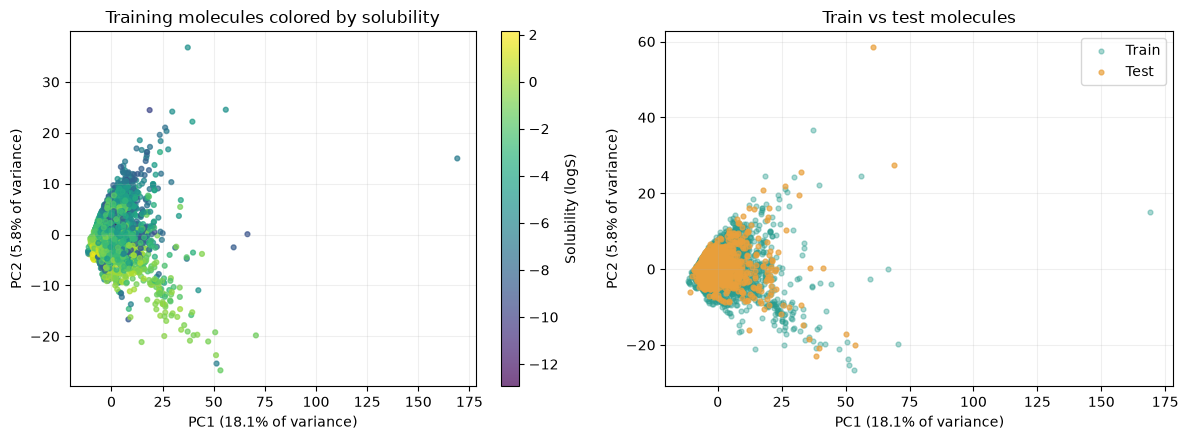

In [9]:
# Graphic visualization 
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Fitted on training molecules only, then applied to the test molecules.
pca_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("constant_features", VarianceThreshold(threshold=0.0)),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=2)),
])
Z_train = pca_pipe.fit_transform(X_train_desc)
Z_test = pca_pipe.transform(X_test_desc)
var = pca_pipe.named_steps["pca"].explained_variance_ratio_ * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sc = axes[0].scatter(Z_train[:, 0], Z_train[:, 1], c=y_train, cmap="viridis", s=12, alpha=0.7)
fig.colorbar(sc, ax=axes[0], label="Solubility (logS)")
axes[0].set_title("Training molecules colored by solubility")

axes[1].scatter(Z_train[:, 0], Z_train[:, 1], color="#2A9D8F", s=12, alpha=0.4, label="Train")
axes[1].scatter(Z_test[:, 0], Z_test[:, 1], color="#E9A03B", s=12, alpha=0.7, label="Test")
axes[1].set_title("Train vs test molecules")
axes[1].legend()

for ax in axes:
    ax.set_xlabel(f"PC1 ({var[0]:.1f}% of variance)")
    ax.set_ylabel(f"PC2 ({var[1]:.1f}% of variance)")
    ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(figures_dir / "fig_descriptor_pca.png", dpi=200)
plt.show()

In [10]:
# Compute Morgan fingerprints for training and test molecules.
X_train_morgan = compute_morgan(train_df["Canonical_smiles"])
X_test_morgan = compute_morgan(test_df["Canonical_smiles"])

# Check the number of molecules and fingerprint dimensions.
assert X_train_morgan.shape[0] == len(y_train)
assert X_test_morgan.shape[0] == len(y_test)
assert X_train_morgan.shape[1] == X_test_morgan.shape[1]

print("Morgan — Train:", X_train_morgan.shape)
print("Morgan — Test:", X_test_morgan.shape)

[22:00:15] WARNING: not removing hydrogen atom without neighbors
[22:00:15] WARNING: not removing hydrogen atom without neighbors
[22:00:15] WARNING: not removing hydrogen atom without neighbors
[22:00:15] WARNING: not removing hydrogen atom without neighbors
[22:00:15] WARNING: not removing hydrogen atom without neighbors
[22:00:15] WARNING: not removing hydrogen atom without neighbors
[22:00:15] WARNING: not removing hydrogen atom without neighbors
[22:00:15] WARNING: not removing hydrogen atom without neighbors
[22:00:15] WARNING: not removing hydrogen atom without neighbors
[22:00:15] WARNING: not removing hydrogen atom without neighbors
[22:00:15] WARNING: not removing hydrogen atom without neighbors
[22:00:15] WARNING: not removing hydrogen atom without neighbors
[22:00:15] WARNING: not removing hydrogen atom without neighbors
[22:00:15] WARNING: not removing hydrogen atom without neighbors
[22:00:15] WARNING: not removing hydrogen atom without neighbors
[22:00:15] WARNING: not r

Morgan — Train: (8354, 2048)
Morgan — Test: (1628, 2048)


In [11]:
# Check fingerprint dimensions and binary values.
assert X_train_morgan.shape == (len(train_df), 2048)
assert X_test_morgan.shape == (len(test_df), 2048)

assert np.isin(X_train_morgan, [0, 1]).all()
assert np.isin(X_test_morgan, [0, 1]).all()

display(X_train_morgan.head())
display(X_test_morgan.head())

,0,1,2,3,4,5,6,7,8,9,...,2038,2039,2040,2041,2042,2043,2044,2045,2046,2047
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


,0,1,2,3,4,5,6,7,8,9,...,2038,2039,2040,2041,2042,2043,2044,2045,2046,2047
12,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
17,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
20,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
27,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
38,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


# 7.1. Save the computed representations

Feature matrices, descriptor names, and molecule order are saved to avoid repeating the expensive RDKit calculations.

In [12]:
# Save both representations to avoid recomputing features.

processed_dir = project_root / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

np.save(
    processed_dir / "Solubility_X_train_desc.npy",
    X_train_desc.to_numpy()
)
np.save(
    processed_dir / "Solubility_X_test_desc.npy",
    X_test_desc.to_numpy()
)
np.save(
    processed_dir / "Solubility_X_train_morgan.npy",
    np.asarray(X_train_morgan)
)
np.save(
    processed_dir / "Solubility_X_test_morgan.npy",
    np.asarray(X_test_morgan)
)

# Save descriptor names and molecule order for reliable reloading.
np.save(
    processed_dir / "Solubility_descriptor_names.npy",
    X_train_desc.columns.to_numpy(dtype=str)
)

train_df[["Canonical_smiles"]].to_csv(
    processed_dir / "Solubility_train_molecule_order.csv", index=False
)
test_df[["Canonical_smiles"]].to_csv(
    processed_dir / "Solubility_test_molecule_order.csv", index=False
)

print("Descriptors and Morgan fingerprints saved.")

Descriptors and Morgan fingerprints saved.


# 8. Scaffold-aware cross-validation and model tuning

All model comparisons use five-fold GroupKFold on the training set only. The scaffold groups are passed to the splitter so that molecules with the same scaffold stay in the same fold. The preprocessing steps are placed inside each pipeline and are therefore fitted separately within each training fold.


In [13]:

# Preprocessing is learned separately within each training fold.

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("constant_features", VarianceThreshold(threshold=0.0)),
    ("model", RandomForestRegressor(
        random_state=0,
        n_jobs=-1, # Use all available CPU cores for parallel processing.
    )),
])


In [14]:
# target the model's parameters inside the pipeline.
rf_param_grid = {
    "model__n_estimators": [100],
    "model__max_depth": [20, None],
    "model__min_samples_leaf": [1, 2, 5],
    "model__max_features": [0.5, 1.0],
}
# Keep molecules with the same scaffold in the same fold.
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=GroupKFold(n_splits=5),
    scoring="neg_root_mean_squared_error",
    refit=True,
)

# Use descriptors, before imputation or scaling.
grid_search.fit(
    X_train_desc,
    y_train,
    groups=groups_train,
)

print("Best parameters:", grid_search.best_params_)
print("Best RMSE (validation):", round(-grid_search.best_score_, 3))

Best parameters: {'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 2, 'model__n_estimators': 100}
Best RMSE (validation): 1.088


# 8.1. Tune and compare the regression models

We first tune Random Forest and XGBoost separately with RDKit descriptors and Morgan fingerprints. Validation RMSE is the selection metric: lower values indicate better solubility predictions. The four searches are then summarized in one table before the final test evaluation.


In [15]:
# Keep a reference to the Random Forest search on descriptors.
grid_rf_desc = grid_search

processed_dir = project_root / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

# Save the best pipeline parameters.
with open(processed_dir / "rf_desc_best_params.json", "w") as f:
    json.dump(grid_rf_desc.best_params_, f, indent=2)

# Save cross-validation results for all tested combinations.
pd.DataFrame(grid_rf_desc.cv_results_).to_csv(
    processed_dir / "rf_desc_grid_search_results.csv",
    index=False,
)

print("Saved in:", processed_dir)
print("Best parameters:", grid_rf_desc.best_params_)
print("Best RMSE (validation):", round(-grid_rf_desc.best_score_, 3))

Saved in: /Users/reginaseca/Documents/M2_AIH/Courses/Cheminformatics/Data-Project-for-Cheminformatics-class/data/processed
Best parameters: {'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 2, 'model__n_estimators': 100}
Best RMSE (validation): 1.088


In [16]:
# Summarize cross-validation results for Random Forest on descriptors.
cv_results = pd.DataFrame(grid_rf_desc.cv_results_)

summary = pd.DataFrame({
    "n_estimators": cv_results["param_model__n_estimators"],
    "max_depth": cv_results["param_model__max_depth"],
    "min_samples_leaf": cv_results["param_model__min_samples_leaf"],
    "max_features": cv_results["param_model__max_features"],
    "RMSE validation": -cv_results["mean_test_score"],
    "RMSE std": cv_results["std_test_score"],
    "Rank": cv_results["rank_test_score"],
})

display(summary.sort_values("Rank").round(3))

,n_estimators,max_depth,min_samples_leaf,max_features,RMSE validation,RMSE std,Rank
7,100,None,2,0.5,1.088,0.111,1
6,100,None,1,0.5,1.089,0.111,2
1,100,20,2,0.5,1.089,0.108,3
0,100,20,1,0.5,1.091,0.107,4
8,100,None,5,0.5,1.094,0.112,5
2,100,20,5,0.5,1.098,0.114,6
10,100,None,2,1.0,1.108,0.116,7
4,100,20,2,1.0,1.108,0.116,8
5,100,20,5,1.0,1.109,0.118,9
11,100,None,5,1.0,1.109,0.118,10


### Random Forest with Morgan fingerprints

Morgan fingerprints encode local structural environments as a fixed-length binary vector. This search uses a smaller parameter grid, because Morgan fingerprints are much slower to fit.


In [17]:
# Pipeline for Random Forest on Morgan fingerprints.
rf_morgan_pipeline = Pipeline([
    ("constant_features", VarianceThreshold(threshold=0.0)),
    ("model", RandomForestRegressor(
        random_state=0,
        n_jobs=-1,
    )),
])

In [18]:
param_grid = {
    "model__n_estimators": [100],
    "model__max_depth": [10, 30],
}

grid_rf_morgan = GridSearchCV(
    estimator=rf_morgan_pipeline,
    param_grid=param_grid,
    cv=GroupKFold(n_splits=5),
    scoring="neg_root_mean_squared_error",
    refit=True,
    verbose=2,
)

grid_rf_morgan.fit(
    X_train_morgan,
    y_train,
    groups=groups_train,
)

Fitting 5 folds for each of 2 candidates, totalling 10 fits
[CV] END .......model__max_depth=10, model__n_estimators=100; total time=   4.6s
[CV] END .......model__max_depth=10, model__n_estimators=100; total time=   4.2s
[CV] END .......model__max_depth=10, model__n_estimators=100; total time=   4.1s
[CV] END .......model__max_depth=10, model__n_estimators=100; total time=   4.1s
[CV] END .......model__max_depth=10, model__n_estimators=100; total time=   4.7s
[CV] END .......model__max_depth=30, model__n_estimators=100; total time=   9.5s
[CV] END .......model__max_depth=30, model__n_estimators=100; total time=   9.6s
[CV] END .......model__max_depth=30, model__n_estimators=100; total time=   9.0s
[CV] END .......model__max_depth=30, model__n_estimators=100; total time=  10.9s
[CV] END .......model__max_depth=30, model__n_estimators=100; total time=  11.4s


GridSearchCV(cv=GroupKFold(n_splits=5),
             estimator=Pipeline(steps=[('constant_features',
                                        VarianceThreshold()),
                                       ('model',
                                        RandomForestRegressor(n_jobs=-1,
                                                              random_state=0))]),
             param_grid={'model__max_depth': [10, 30],
                         'model__n_estimators': [100]},
             scoring='neg_root_mean_squared_error', verbose=2)

In [19]:
cv_results_morgan = pd.DataFrame(grid_rf_morgan.cv_results_)

summary_morgan = pd.DataFrame({
    "n_estimators": cv_results_morgan["param_model__n_estimators"],
    "max_depth": cv_results_morgan["param_model__max_depth"],
    "RMSE validation": -cv_results_morgan["mean_test_score"],
    "RMSE std": cv_results_morgan["std_test_score"],
    "Rank": cv_results_morgan["rank_test_score"],
})

display(summary_morgan.sort_values("Rank").round(3))

,n_estimators,max_depth,RMSE validation,RMSE std,Rank
1,100,30,1.786,0.183,1
0,100,10,1.975,0.125,2


In [20]:
# Save the Random Forest search results for Morgan fingerprints.

processed_dir = project_root / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

# Save the best pipeline parameters.
with open(processed_dir / "rf_morgan_best_params.json", "w") as f:
    json.dump(grid_rf_morgan.best_params_, f, indent=2)

# Save cross-validation results for all tested combinations.
pd.DataFrame(grid_rf_morgan.cv_results_).to_csv(
    processed_dir / "rf_morgan_grid_search_results.csv",
    index=False,
)

print("Saved in:", processed_dir)
print("Best parameters:", grid_rf_morgan.best_params_)
print("Best RMSE (validation):", round(-grid_rf_morgan.best_score_, 3))

Saved in: /Users/reginaseca/Documents/M2_AIH/Courses/Cheminformatics/Data-Project-for-Cheminformatics-class/data/processed
Best parameters: {'model__max_depth': 30, 'model__n_estimators': 100}
Best RMSE (validation): 1.786


### XGBoost with both representations

XGBoost is evaluated with RDKit descriptors and Morgan fingerprints using the same grouped folds. The descriptor pipeline imputes missing values and scales the descriptors inside each fold; the Morgan pipeline only removes constant bits.


In [21]:
# Use identical scaffold-based folds for both representations.
cv = GroupKFold(n_splits=5)

# More efficient to use a grid dictionary for each representation, with the larger grid for `desc` and the original smaller grid for `morgan`.

xgb_param_grids = {
    "desc": {
        "model__n_estimators": [100, 200, 400],
        "model__max_depth": [3, 6],
        "model__learning_rate": [0.1],
        "model__subsample": [0.8, 1.0],
        "model__colsample_bytree": [0.8, 1.0],
    },
    "morgan": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [3, 6],
        "model__learning_rate": [0.05, 0.1],
    },
}

xgb_searches = {}
xgb_summary_rows = []

for representation, X_features in [
    ("desc", X_train_desc),
    ("morgan", X_train_morgan),
]:
    # Imputation and scaling are needed only for the descriptor pipeline.
    steps = []

    if representation == "desc":
        steps.append(("imputer", SimpleImputer(strategy="median")))

    steps.append(
        ("constant_features", VarianceThreshold(threshold=0.0))
    )

    if representation == "desc":
        steps.append(("scaler", MinMaxScaler()))

    steps.append((
        "model",
        XGBRegressor(
            objective="reg:squarederror",
            random_state=0,
            n_jobs=-1,
            verbosity=0,
        ),
    ))

    search = GridSearchCV(
        estimator=Pipeline(steps),
        param_grid=xgb_param_grids[representation],
        cv=cv,
        scoring="neg_root_mean_squared_error",
        refit=True,
        return_train_score=True,
        error_score="raise",
        verbose=2,
    )

    print(f"\nXGBoost — {representation}")

    search.fit(
        X_features,
        y_train,
        groups=groups_train,
    )

    xgb_searches[representation] = search

    # Save results immediately after each completed search.
    pd.DataFrame(search.cv_results_).to_csv(
        processed_dir / f"xgb_{representation}_grid_search_results.csv",
        index=False,
    )

    with open(
        processed_dir / f"xgb_{representation}_best_params.json", "w"
    ) as f:
        json.dump(search.best_params_, f, indent=2)

    best_idx = search.best_index_

    xgb_summary_rows.append({
        "Model": "XGBoost",
        "Representation": representation,
        "RMSE validation": -search.best_score_,
        "RMSE std": search.cv_results_["std_test_score"][best_idx],
        "Best parameters": search.best_params_,
    })




XGBoost — desc
Fitting 5 folds for each of 24 candidates, totalling 120 fits
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.1, model__max_depth=3, model__n_estimators=100, model__subsample=0.8; total time=   0.5s
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.1, model__max_depth=3, model__n_estimators=100, model__subsample=0.8; total time=   0.3s
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.1, model__max_depth=3, model__n_estimators=100, model__subsample=0.8; total time=   0.3s
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.1, model__max_depth=3, model__n_estimators=100, model__subsample=0.8; total time=   0.4s
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.1, model__max_depth=3, model__n_estimators=100, model__subsample=0.8; total time=   0.4s
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.1, model__max_depth=3, model__n_estimators=100, model__subsample=1.0; total time=   0.3s
[CV] END model__colsam

In [22]:
# Keep named references to the fitted searches.
grid_xgb_desc = xgb_searches["desc"]
grid_xgb_morgan = xgb_searches["morgan"]

display(
    pd.DataFrame(xgb_summary_rows)
    .sort_values("RMSE validation")
    .round(3)
)

,Model,Representation,RMSE validation,RMSE std,Best parameters
0,XGBoost,desc,1.046,0.111,"{'model__colsample_bytree': 0.8, 'model__learn..."
1,XGBoost,morgan,1.660,0.093,"{'model__learning_rate': 0.1, 'model__max_dept..."


### Compare validation performance

This table brings together the best validation result from each search. The standard deviation indicates how much RMSE changes across scaffold folds, so small differences should be interpreted together with this uncertainty.


In [23]:
# Compare the four tuned model–representation combinations.
searches = {
    "RF + descriptors": grid_rf_desc,
    "RF + Morgan": grid_rf_morgan,
    "XGBoost + descriptors": grid_xgb_desc,
    "XGBoost + Morgan": grid_xgb_morgan,
}

comparison = pd.DataFrame([
    {
        "Model": name,
        "RMSE validation": -search.best_score_,
        "RMSE std": search.cv_results_["std_test_score"][
            search.best_index_
        ],
        "Best parameters": search.best_params_,
    }
    for name, search in searches.items()
]).sort_values("RMSE validation")

display(comparison.round(3))


,Model,RMSE validation,RMSE std,Best parameters
2,XGBoost + descriptors,1.046,0.111,"{'model__colsample_bytree': 0.8, 'model__learn..."
0,RF + descriptors,1.088,0.111,"{'model__max_depth': None, 'model__max_feature..."
3,XGBoost + Morgan,1.660,0.093,"{'model__learning_rate': 0.1, 'model__max_dept..."
1,RF + Morgan,1.786,0.183,"{'model__max_depth': 30, 'model__n_estimators'..."


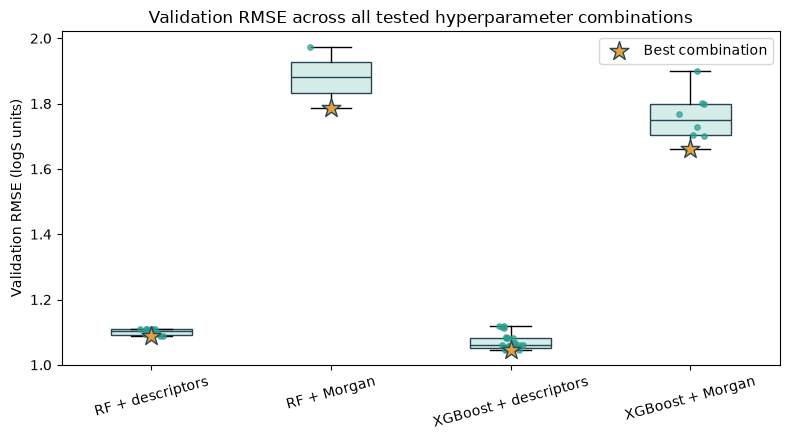

In [24]:
# Graphical overview (Each point represents a tested hyperparameter combination, and the star marks the best one.)
fig, ax = plt.subplots(figsize=(8, 4.5))

data = [-s.cv_results_["mean_test_score"] for s in searches.values()]
bp = ax.boxplot(data, patch_artist=True, showfliers=False)
for box in bp["boxes"]:
    box.set(facecolor="#D5ECE9", edgecolor="#264653")
for median in bp["medians"]:
    median.set(color="#264653")

rng = np.random.default_rng(0)
for i, values in enumerate(data, start=1):
    ax.scatter(rng.normal(i, 0.05, len(values)), values,
               color="#2A9D8F", s=15, alpha=0.7, zorder=3)

best = [-s.best_score_ for s in searches.values()]
ax.scatter(range(1, len(best) + 1), best, marker="*", s=200, color="#E9A03B",
           edgecolor="#264653", zorder=4, label="Best combination")

ax.set_xticks(range(1, len(searches) + 1))
ax.set_xticklabels(searches.keys(), rotation=15)
ax.set_ylabel("Validation RMSE (logS units)")
ax.set_title("Validation RMSE across all tested hyperparameter combinations")
ax.legend()
fig.tight_layout()
fig.savefig(figures_dir / "fig_tuning_overview.png", dpi=200)
plt.show()

# 9. Select the final model and evaluate the held-out test set

The model with the lowest scaffold-aware validation RMSE is selected from the four tuned searches. Its pipeline has already been refitted on all training molecules by GridSearchCV. We then predict the untouched test set once and report RMSE, MAE, R², and individual predictions. The test set is not used for model selection.


### Final test evaluation

The selected pipeline is evaluated once on molecules from scaffolds that were not used during training. RMSE emphasizes large errors, MAE gives the average absolute error in solubility units, and R² measures the proportion of target variability explained by the model. The prediction table also stores residuals, which can be inspected to identify molecules that are unusually difficult to predict.


In [25]:
# Select the tuned model with the lowest cross-validation RMSE.
searches = {
    "RF + descriptors": grid_rf_desc,
    "RF + Morgan": grid_rf_morgan,
    "XGBoost + descriptors": grid_xgb_desc,
    "XGBoost + Morgan": grid_xgb_morgan,
}

best_model_name = max(
    searches,
    key=lambda name: searches[name].best_score_,
)

# Retrieve the fitted pipeline and its matching test representation.
final_model = searches[best_model_name].best_estimator_

X_selected_test = (
    X_test_desc
    if best_model_name.endswith("descriptors")
    else X_test_morgan
)

# Predict directly: GridSearchCV already refitted the best pipeline.
y_test_pred = final_model.predict(X_selected_test)

final_test_results = pd.DataFrame([{
    "Model": best_model_name,
    "RMSE": mean_squared_error(y_test, y_test_pred) ** 0.5,
    "MAE": mean_absolute_error(y_test, y_test_pred),
    "R2": r2_score(y_test, y_test_pred),
}])

# Store predictions and residuals for later analysis.
test_predictions = test_df[
    ["Drug_ID", "Canonical_smiles", "Solubility"]
].copy()

test_predictions["predicted_solubility"] = y_test_pred
test_predictions["residual"] = (
    test_predictions["Solubility"] - y_test_pred
)
test_predictions["model"] = best_model_name

print("Selected model:", best_model_name)
display(final_test_results.round(3))
display(test_predictions.head())

Selected model: XGBoost + descriptors


,Model,RMSE,MAE,R2
0,XGBoost + descriptors,1.028,0.693,0.81


,Drug_ID,Canonical_smiles,Solubility,predicted_solubility,residual,model
12,"2,3-dimethylphenol; 2,4-dimethylphenol; 2,5-di...",Cc1cc(C)cc(O)c1.Cc1ccc(C)c(O)c1.Cc1ccc(O)c(C)c...,-1.980310,-5.071651,3.091341,XGBoost + descriptors
17,zinc bis[O-(2-ethylhexyl) O-isobutyl dithiopho...,CCCCC(CC)COP(=S)([S-])OCC(C)C.CCCCC(CC)COP(=S)...,-2.958195,-3.962107,1.003912,XGBoost + descriptors
20,2-methylheptyl 3-sulfanylpropanoate,CC(C)CCCCCOC(=O)CCS,-4.454382,-4.258370,-0.196011,XGBoost + descriptors
27,"(1S,5S)-6,6-dimethyl-2-methylidenebicyclo[3.1....",C=C1CCC2CC1C2(C)C,-4.292313,-4.463838,0.171524,XGBoost + descriptors
38,molybdenum,[Mo],-4.203848,-6.256693,2.052844,XGBoost + descriptors


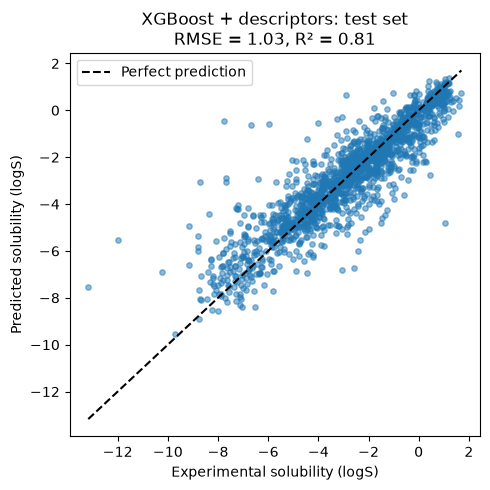

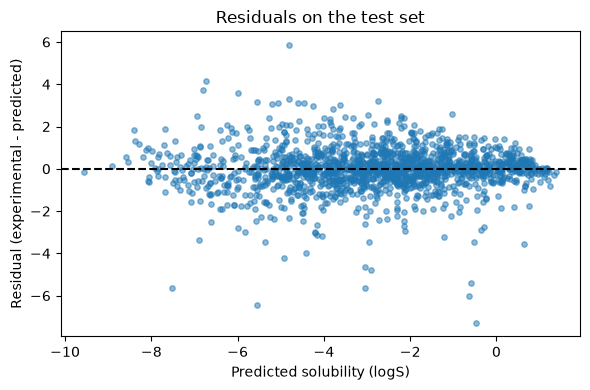

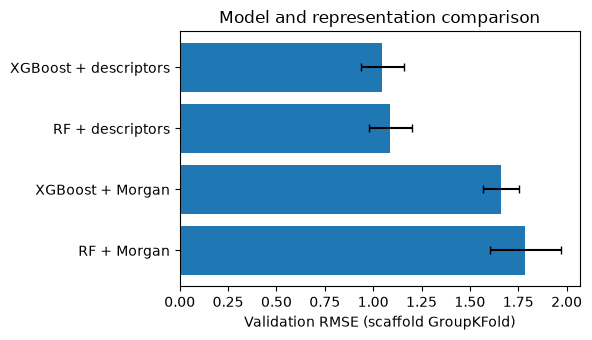

In [26]:
#Graphical visualization 

import matplotlib.pyplot as plt

results_dir = project_root / "results"
results_dir.mkdir(exist_ok=True)

# Figure 1: predicted vs experimental solubility on the held-out test set.
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_test, y_test_pred, alpha=0.5, s=15)
lims = [min(y_test.min(), y_test_pred.min()), max(y_test.max(), y_test_pred.max())]
ax.plot(lims, lims, "k--", label="Perfect prediction")
ax.set_xlabel("Experimental solubility (logS)")
ax.set_ylabel("Predicted solubility (logS)")
ax.set_title(f"{best_model_name}: test set\n"
             f"RMSE = {final_test_results['RMSE'][0]:.2f}, R² = {final_test_results['R2'][0]:.2f}")
ax.legend()
fig.tight_layout()
fig.savefig(results_dir / "fig_predicted_vs_actual.png", dpi=200)
plt.show()

# Figure 2: residuals against predicted values.
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(test_predictions["predicted_solubility"], test_predictions["residual"],
           alpha=0.5, s=15)
ax.axhline(0, color="k", linestyle="--")
ax.set_xlabel("Predicted solubility (logS)")
ax.set_ylabel("Residual (experimental - predicted)")
ax.set_title("Residuals on the test set")
fig.tight_layout()
fig.savefig(results_dir / "fig_residuals.png", dpi=200)
plt.show()

# Figure 3: validation RMSE of the four tuned models (error bars = std across folds).
comp = comparison.sort_values("RMSE validation", ascending=False)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.barh(comp["Model"], comp["RMSE validation"], xerr=comp["RMSE std"], capsize=3)
ax.set_xlabel("Validation RMSE (scaffold GroupKFold)")
ax.set_title("Model and representation comparison")
fig.tight_layout()
fig.savefig(results_dir / "fig_model_comparison.png", dpi=200)
plt.show()

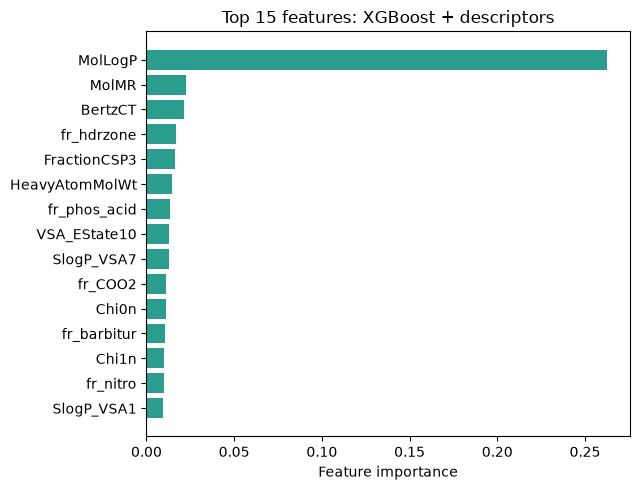

In [27]:
# Figure 4: feature importance for the selected model (saves the most important features in the final model)
input_names = np.array([str(c) for c in X_selected_test.columns], dtype=object)
feature_names = final_model[:-1].get_feature_names_out(input_names)

importances = pd.Series(
    final_model.named_steps["model"].feature_importances_, index=feature_names
).nlargest(15)

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.barh(importances.index[::-1], importances.values[::-1], color="#2A9D8F")
ax.set_xlabel("Feature importance")
ax.set_title(f"Top 15 features: {best_model_name}")
fig.tight_layout()
fig.savefig(figures_dir / "fig_feature_importance.png", dpi=200)
plt.show()

In [28]:
# Save the final comparison, selected-model metrics, predictions, and parameters.
results_dir = project_root / "results"
results_dir.mkdir(exist_ok=True)

comparison.to_csv(results_dir / "solubility_tuned_cv_results.csv", index=False)
final_test_results.to_csv(results_dir / "solubility_test_results.csv", index=False)
test_predictions.to_csv(results_dir / "solubility_test_predictions.csv", index=False)

best_params = {
    name: search.best_params_
    for name, search in searches.items()
}
with (results_dir / "solubility_best_params.json").open("w") as handle:
    json.dump(best_params, handle, indent=2)


**Conclusion and summary**


(I will complete after restarting the kernel and running all)